# Preprocessing Comparison

Compare preprocessing strategies on governed public datasets using the same
feature extractor, to understand whether center-crop normalization is sufficient
or whether alternative strategies improve embedding behavior.

> **Warning:** Results are diagnostic only. Public datasets (FabricNET, LeaData)
> are not luxury authentication datasets. These experiments do not prove
> authentication accuracy. Center-crop remains the backend default until
> evidence from real microscopy data supports a change.

## Curated Results

See [Preprocessing Comparison Results](../docs/datasets/preprocessing-comparison-results.md)
for the full curated summary including cross-dataset interpretation and recommendations.

## Strategies

| Strategy | Description |
|---|---|
| `center_crop_512` | Current backend default. Center crop to square, resize 512x512. |
| `padded_resize_512` | Fit within 512x512 preserving aspect ratio, reflect-pad remainder. |
| `five_crop_512` | Five crops (center + 4 corners), embed each, average + L2-normalize. |
| `grayscale_center_crop_512` | Center crop, convert to grayscale (3-channel RGB). Tests color dependence. |
| `clahe_center_crop_512` | Center crop + CLAHE on luminance. Enhances local contrast. |
| `tile_224_average` | Non-overlapping 224x224 tiles, embed each, average + L2-normalize. |

## Run Experiments

From `auth-platform/`:

```bash
# FabricNET full (130 images, all strategies, ~3.5 min)
make preprocessing-experiment-fabricnet

# LeaData quick (50 images, 3 strategies, ~23s)
make preprocessing-experiment-leadata-quick

# LeaData medium (200 images, 3 strategies, ~92s)
make preprocessing-experiment-leadata-medium

# LeaData full (1,200 images, all strategies — schedule overnight)
make preprocessing-experiment-leadata

# Custom
python scripts/run_preprocessing_experiment.py --dataset external_fabricnet_v0.1.0 --strategies center_crop_512,padded_resize_512 --limit 50
```

In [1]:
import json
from pathlib import Path

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

# Configuration — change dataset as needed
DATASET = "external_fabricnet_v0.1.0"
EXTRACTOR = "texture_baseline_v0.2.0"

METRICS_DIR = Path("../experiments/outputs/preprocessing-comparison")
ds_tag = DATASET.replace(".", "_")
ext_tag = EXTRACTOR.replace(".", "_")
metrics_path = METRICS_DIR / f"{ds_tag}__{ext_tag}__preprocessing_metrics.json"

print(f"Looking for: {metrics_path}")
print(f"Exists: {metrics_path.exists()}")

Looking for: ../experiments/outputs/preprocessing-comparison/external_fabricnet_v0_1_0__texture_baseline_v0_2_0__preprocessing_metrics.json
Exists: True


In [2]:
# Load metrics
if not metrics_path.exists():
    print("No metrics file found. Run the experiment first:")
    print(f"  make preprocessing-experiment-fabricnet")
    data = None
else:
    data = json.loads(metrics_path.read_text())
    print(f"Dataset:   {data['dataset_version']}")
    print(f"Extractor: {data['extractor']}")
    print(f"Strategies: {len(data['strategies'])}")
    print()

    # Display as table
    header = f"{'Strategy':<28} {'Dim':>5} {'ClustSep':>10} {'NN Agree':>10} {'R@1':>8} {'R@3':>8} {'R@5':>8}"
    print(header)
    print("-" * len(header))
    for s in data["strategies"]:
        m = s["metrics"]
        print(f"{s['strategy']:<28} {s['embedding_dimension']:>5} "
              f"{m.get('cluster_separation', 0):>10.4f} "
              f"{m.get('nn_agreement_rate', 0):>9.1%} "
              f"{m.get('recall_at_1', 0):>8.4f} "
              f"{m.get('recall_at_3', 0):>8.4f} "
              f"{m.get('recall_at_5', 0):>8.4f}")

Dataset:   external_fabricnet_v0.1.0
Extractor: texture_baseline_v0.2.0
Strategies: 6

Strategy                       Dim   ClustSep   NN Agree      R@1      R@3      R@5
-----------------------------------------------------------------------------------
center_crop_512                256     0.9242    100.0%   1.0000   1.0000   1.0000
padded_resize_512              256     0.9242    100.0%   1.0000   1.0000   1.0000
five_crop_512                  256     0.9247    100.0%   1.0000   1.0000   1.0000
grayscale_center_crop_512      256     0.9253    100.0%   1.0000   1.0000   1.0000
clahe_center_crop_512          256     0.9698    100.0%   1.0000   1.0000   1.0000
tile_224_average               256     0.9284    100.0%   1.0000   1.0000   1.0000


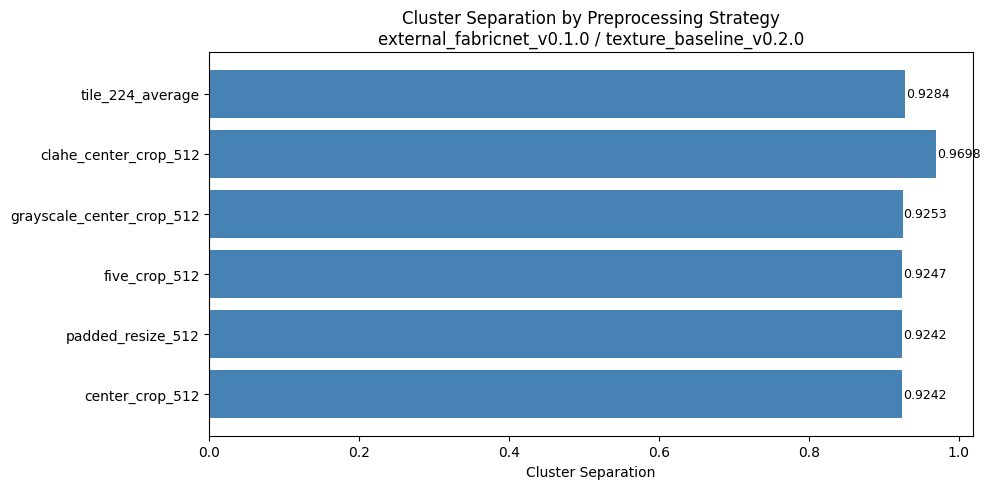

In [3]:
# Bar chart: Cluster Separation by Strategy
if data:
    strategies = [s["strategy"] for s in data["strategies"]]
    cluster_seps = [s["metrics"].get("cluster_separation", 0) for s in data["strategies"]]

    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.barh(strategies, cluster_seps, color="steelblue")
    ax.set_xlabel("Cluster Separation")
    ax.set_title(f"Cluster Separation by Preprocessing Strategy\n{DATASET} / {EXTRACTOR}")
    ax.axvline(x=0, color="gray", linewidth=0.5)
    for bar, val in zip(bars, cluster_seps):
        ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height() / 2,
                f"{val:.4f}", va="center", fontsize=9)
    plt.tight_layout()
    plt.savefig("_preprocessing_cluster_sep.png", dpi=100)
    plt.show()
else:
    print("No data to plot.")

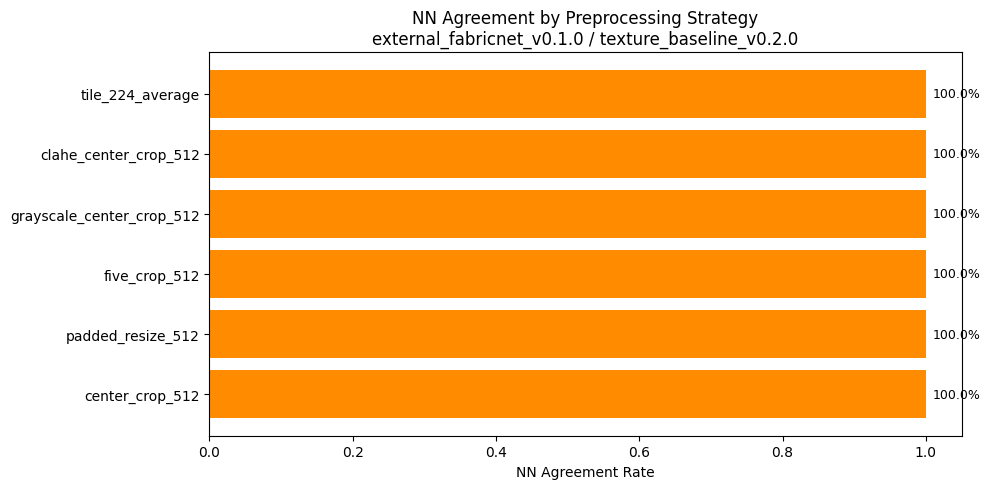

In [4]:
# Bar chart: NN Agreement by Strategy
if data:
    nn_agrees = [s["metrics"].get("nn_agreement_rate", 0) for s in data["strategies"]]

    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.barh(strategies, nn_agrees, color="darkorange")
    ax.set_xlabel("NN Agreement Rate")
    ax.set_title(f"NN Agreement by Preprocessing Strategy\n{DATASET} / {EXTRACTOR}")
    ax.set_xlim(0, 1.05)
    for bar, val in zip(bars, nn_agrees):
        ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
                f"{val:.1%}", va="center", fontsize=9)
    plt.tight_layout()
    plt.savefig("_preprocessing_nn_agree.png", dpi=100)
    plt.show()
else:
    print("No data to plot.")

In [5]:
# Load LeaData results for side-by-side comparison (optional)
leadata_path = METRICS_DIR / f"external_leadata_v0_1_0__{ext_tag}__preprocessing_metrics.json"
if leadata_path.exists():
    leadata = json.loads(leadata_path.read_text())
    print(f"LeaData: {leadata['dataset_version']}")
    for s in leadata["strategies"]:
        m = s["metrics"]
        print(f"  {s['strategy']:<28} cluster_sep={m.get('cluster_separation', 0):.4f}  "
              f"nn_agree={m.get('nn_agreement_rate', 0):.1%}")
else:
    print(f"No LeaData results at {leadata_path}")

LeaData: external_leadata_v0.1.0
  center_crop_512              cluster_sep=0.9428  nn_agree=100.0%
  padded_resize_512            cluster_sep=0.9446  nn_agree=100.0%
  clahe_center_crop_512        cluster_sep=0.9697  nn_agree=100.0%


## Notes / Conclusions

- Center-crop (512x512) is the current backend default and the baseline for comparison.
- Padded resize preserves the full field of view — useful if important texture is near image edges.
- Five-crop aggregation tests whether multiple views improve embedding stability.
- Grayscale tests color dependence — if results are similar, color adds little to texture features.
- CLAHE tests whether local contrast enhancement helps the hand-crafted feature extractor.
- Tile-based embedding is a proxy for future patch-based approaches.

**These results are diagnostic only.** They do not prove authentication accuracy.
Public datasets are not luxury authentication datasets. Center-crop remains the
backend default until evidence from real microscopy data supports a change.